# Scenarios, credibility and the standardised measurement approach

**Question:** How does the standardised measurement approach turn the size of a bank and ten years of its losses into capital, how much does one large loss move it, and how much do eight expert scenarios move the distribution-based capital?


- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- compute the business indicator, its component and bucket, the loss component, the internal loss multiplier and the capital of the standardised measurement approach (SMA) with the engine, and check each against the formula and the golden value of the Basel text;
- show how one large loss moves the SMA capital through the multiplier, and read the `oprisk.sma_ilm_response` test;
- turn expert scenarios into a tail: as pseudo-observations, as a fitted tail, and as a Gamma prior updated by the loss data (Bayesian credibility);
- measure how much each scenario moves the capital, and read the `oprisk.scenario_influence` test.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The generator of case C17 and its estimators live in `data-pipeline/pipeline/cases/c17/`, which is not an installed package: this notebook loads those modules by path (importing the whole `pipeline` package would import every case and its heavy dependencies). The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import distributions, scenarios, sma
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

All from case C17, variant with tail index 0.8, for the synthetic bank of EUR 50 billion in assets.

- **File read:** `data/derived/C17/xi-0-8.json`: `outputs.bank` (the business indicator the case states), `outputs.sma_response` (the SMA after adding one large loss to a history), `outputs.scenario_influence` (the eight expert scenarios and the influence of each on the capital) and the matching rows of `tests`. `data/derived/C17/models-generator.json` holds the SMA specification with its golden value.
- **Histories:** the SMA reads annual losses, and the committed documents hold summaries, not histories. As in notebook 02, the case's generator is loaded by path and regenerates the history behind each committed block from the seed the block records.
- **What is synthetic:** the three years of income and expense items of the bank and the scenarios are invented by the case; the synthetic bank is not presented as a real one.

The next cell loads the documents and the generator and prints the seeds of the two blocks.

In [2]:
# Load the variant document and the generator document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
LANG = "en"
variant_doc = json.loads((ROOT / "data" / "derived" / "C17" / "xi-0-8.json").read_text(encoding="utf-8"))
generator_doc = json.loads((ROOT / "data" / "derived" / "C17" / "models-generator.json").read_text(encoding="utf-8"))
bank = variant_doc["outputs"]["bank"]
response = variant_doc["outputs"]["sma_response"]
influence_block = variant_doc["outputs"]["scenario_influence"]
print("bank:", bank["label"][LANG])
print(
    "seed of the SMA response block:", response["seed"], response["cell_id"], "| seed of the scenario block:",
    influence_block["seed"], influence_block["cell_id"]
)
print(
    "baked by riskvalidation", variant_doc["provenance"]["riskvalidation_version"], "| installed",
    md.version("riskvalidation")
)

bank: Synthetic bank of EUR 50 billion in assets
seed of the SMA response block: 4208000 y10-h20000 | seed of the scenario block: 4208002 y10-h20000
baked by riskvalidation 1.0.1 | installed 1.0.1


The generator of the case is loaded by path, under a throwaway package name, so that nothing else of the pipeline is imported; `sys.dont_write_bytecode` keeps the import from leaving cache files in the repository. Besides the generator and the case constants, the notebook uses two functions of the case's own `replicate.py` that compose engine calls for the scenario rung: `scenario_prior` (the choice of the bootstrap seed) and `scenario_capital`. The estimation itself is the engine's.

In [3]:
# Load the case's generator, constants and scenario helpers from data-pipeline/ by path
sys.dont_write_bytecode = True
shell = types.ModuleType("c17")
shell.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = shell
from c17 import generator, params as case_params, replicate

variant = generator.variant(0.8)
H = 20_000.0
print("true tail index:", variant.tail_index, "| collection threshold (EUR):", int(H))

true tail index: 0.8 | collection threshold (EUR): 20000


## Method

Part A follows the standardised measurement approach (SMA) of the Basel framework, OPE25 (BCBS, Basel Framework): it computes a capital from the size of the bank and its own loss history, with no distribution. Part B turns expert scenarios into a tail and measures their influence. Both end in a capital that can be put beside the LDA capital of the earlier notebooks.

### A1: the business indicator

The business indicator is the sum of three components built from the last three years of income and expense items (OPE25.4 and OPE25.5): the interest, leases and dividend component, the services component and the financial component,

$$\mathrm{ILDC} = \min\big(\overline{|II - IE|},\; 0.0225\,\overline{IEA}\big) + \overline{DI}, \quad \mathrm{SC} = \max(\overline{OOI}, \overline{OOE}) + \max(\overline{FI}, \overline{FE}), \quad \mathrm{FC} = \overline{|PL_{TB}|} + \overline{|PL_{BB}|}$$

where a bar is the three-year average, absolute values of net items taken year by year before averaging, and $\mathrm{BI} = \mathrm{ILDC} + \mathrm{SC} + \mathrm{FC}$. The case states the bank's three years of items in `params.BANK`. The next cell prints the averages that enter each formula, calls the engine's four functions, and compares the result with the document.

In [4]:
# The averages inside each formula, the engine's four functions, and the document's business indicator
items = {key: np.array(values, dtype=float) for key, values in case_params.BANK.items()}
print(
    "mean |II - IE| = %.3e | 0.0225 * mean IEA = %.3e | mean DI = %.3e" % (
        np.abs(items["ii"] - items["ie"]).mean(), 0.0225 * items["iea"].mean(), items["di"].mean()
    )
)
print(
    "max(mean OOI, mean OOE) = %.3e | max(mean FI, mean FE) = %.3e" % (
        max(items["ooi"].mean(), items["ooe"].mean()), max(items["fi"].mean(), items["fe"].mean())
    )
)
print("mean |PL_TB| = %.3e | mean |PL_BB| = %.3e" % (np.abs(items["pl_tb"]).mean(), np.abs(items["pl_bb"]).mean()))
ildc = sma.ildc(items["ii"], items["ie"], items["iea"], items["di"])
service = sma.service_component(items["ooi"], items["ooe"], items["fi"], items["fe"])
financial = sma.financial_component(items["pl_tb"], items["pl_bb"])
bi = sma.business_indicator(ildc, service, financial)
print("ILDC = %.3e | SC = %.3e | FC = %.3e | BI = %.3e" % (ildc, service, financial, bi))
print("document: ", {k: "%.3e" % v for k, v in bank["business_indicator"].items()})

mean |II - IE| = 7.000e+08 | 0.0225 * mean IEA = 1.012e+09 | mean DI = 1.000e+08
max(mean OOI, mean OOE) = 1.000e+08 | max(mean FI, mean FE) = 4.000e+08
mean |PL_TB| = 5.000e+07 | mean |PL_BB| = 5.000e+07
ILDC = 8.000e+08 | SC = 5.000e+08 | FC = 1.000e+08 | BI = 1.400e+09
document:  {'ildc_eur': '8.000e+08', 'sc_eur': '5.000e+08', 'fc_eur': '1.000e+08', 'bi_eur': '1.400e+09'}


### A2: the business indicator component and the bucket

The component is a marginal-rate schedule on the indicator, with 12% up to EUR 1 billion, 15% from 1 to 30 billion and 18% above (OPE25.7, Table 1), and the bucket is 1, 2 or 3 by the same limits:

$$\mathrm{BIC} = 0.12\,\min(\mathrm{BI}, 10^9) + 0.15\,\big(\min(\mathrm{BI}, 30\cdot10^9) - 10^9\big)^+ + 0.18\,\big(\mathrm{BI} - 30\cdot10^9\big)^+$$

The Basel text gives a golden value: an indicator of EUR 35 billion has a component of EUR 5.37 billion (OPE25.7, footnote 2), which we can add by hand: $0.12 \cdot 1 + 0.15 \cdot 29 + 0.18 \cdot 5 = 5.37$ billion. The next cell checks the golden value with `bic`, then the bank's own component and bucket.

In [5]:
# The golden value of OPE25.7 by hand and by the engine, then the bank's component and bucket
golden = generator_doc["fit"]["sma"]["golden"]
by_hand = 0.12 * 1e9 + 0.15 * 29e9 + 0.18 * 5e9
print(
    "BI = %.1e | by hand %.4e | engine %.4e | golden in the document %.4e" % (
        golden["bi_eur"], by_hand, sma.bic(golden["bi_eur"]), golden["bic_eur"]
    )
)
bic_bank = sma.bic(bi)
print(
    "bank: BI = %.2e | BIC = %.4e | bucket %d | document: BIC = %.4e, bucket %d" % (
        bi, bic_bank, sma.bic_bucket(bi), bank["bic_eur"], bank["bucket"]
    )
)

BI = 3.5e+10 | by hand 5.3700e+09 | engine 5.3700e+09 | golden in the document 5.3700e+09
bank: BI = 1.40e+09 | BIC = 1.8000e+08 | bucket 2 | document: BIC = 1.8000e+08, bucket 2


### A3: the loss component and the internal loss multiplier

The bank's own losses enter through the loss component, 15 times the average annual loss of the last ten years, and the multiplier compares it with the business indicator component (OPE25.8 and OPE25.9):

$$\mathrm{LC} = 15 \cdot \overline{L}_{10}, \qquad \mathrm{ILM} = \ln\!\Big(e - 1 + \big(\mathrm{LC}/\mathrm{BIC}\big)^{0.8}\Big), \qquad \mathrm{ORC} = \mathrm{BIC} \cdot \mathrm{ILM}$$

When $\mathrm{LC} = \mathrm{BIC}$ the multiplier is exactly 1, and above it the multiplier exceeds 1. The next cell regenerates the history behind the committed response block (seed and cell from the document), records the losses above the threshold, and computes the loss component, the multiplier and `sma_capital`, which also applies the rule that fewer than five years of data give the component only (OPE25.10 and OPE25.15). It compares with the first row of the committed block, baked by an earlier engine release.

In [6]:
# Regenerate the history of the response block and compute the SMA step by step
history = generator.draw_history(variant, response["seed"], 10).recorded(H)
annual = history.annual
lc = sma.loss_component(annual)
ilm_value = sma.ilm(lc, bic_bank)
result = sma.sma_capital(bi, annual)
first = response["rows"][0]
print("average annual loss (EUR): %.1f | LC = 15 x = %.1f | LC / BIC = %.4f" % (annual.mean(), lc, lc / bic_bank))
print(
    "ILM = %.9f | ORC = %.1f | basis %s | discretion %s" % (
        ilm_value, result.orc, result.basis, result.discretion_applied
    )
)
print("committed first row: LC = %.1f | ILM = %.9f | ORC = %.1f" % (first["lc_eur"], first["ilm"], first["orc_eur"]))
print("ILM when LC = BIC:", sma.ilm(bic_bank, bic_bank))
short = sma.sma_capital(bi, annual[:4])
print(
    "with 4 years of losses: basis %s | discretion %s | ORC = BIC = %.1f" % (
        short.basis, short.discretion_applied, short.orc
    )
)
print(
    md.version("riskvalidation")
)

average annual loss (EUR): 5005390.8 | LC = 15 x = 75080861.7 | LC / BIC = 0.4171
ILM = 0.795301641 | ORC = 143154295.3 | basis bic-times-ilm | discretion none
committed first row: LC = 75080861.7 | ILM = 0.795301641 | ORC = 143154295.0
ILM when LC = BIC: 1.0
with 4 years of losses: basis bic-only | discretion transitional-bic-only | ORC = BIC = 180000000.0
1.0.1


The next cell draws the multiplier of the formula: the internal loss multiplier as a function of the loss component over the business indicator component, with the bank's own history marked on it.

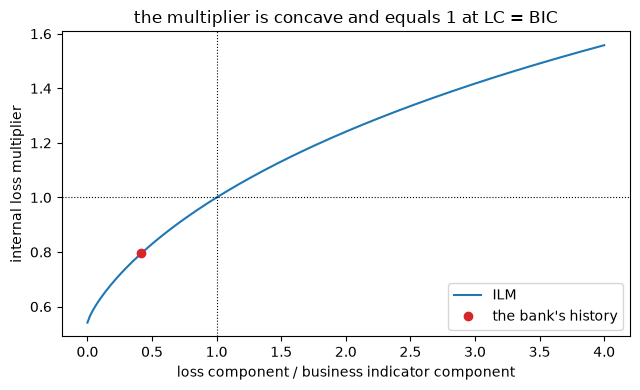

In [7]:
# Draw the internal loss multiplier against the loss component over the business indicator component
fig, ax = plt.subplots(figsize=(6.5, 4.0))
ratio = np.linspace(0.0, 4.0, 200)
ax.plot(ratio, [sma.ilm(r * bic_bank, bic_bank) for r in ratio], color="tab:blue", label="ILM")
ax.axhline(1.0, color="black", linestyle=":", linewidth=0.8)
ax.axvline(1.0, color="black", linestyle=":", linewidth=0.8)
ax.plot([lc / bic_bank], [ilm_value], "o", color="tab:red", label="the bank's history")
ax.set_xlabel("loss component / business indicator component")
ax.set_ylabel("internal loss multiplier")
ax.set_title("the multiplier is concave and equals 1 at LC = BIC")
ax.legend()
fig.tight_layout()
plt.show()

The curve starts at zero loss with a multiplier below 1, crosses 1 where the loss component equals the business indicator component (both dotted lines meet on it, the printed `ILM when LC = BIC: 1.0`) and flattens afterwards, so a bank with four times the expected losses does not pay four times the capital. The bank's own ten years put it at 0.4171 of the component and a multiplier of 0.795302, on the rising part of the curve, where each extra euro of loss history still moves the capital noticeably. The curve is the formula, not a calibration to any bank.

### A4: what one large loss does to the SMA

Because the loss component averages ten years, a single large loss moves it by one tenth of fifteen times its size, and the multiplier by the concave map above. The case adds to the latest year a loss of 0, 0.1, 0.25, 0.5 and 1 times the BIC, and records the capital each time. The test `oprisk.sma_ilm_response` summarises the jump of the multiplier when a loss of half the BIC is added: its metric is the multiplier after minus the multiplier before, and the light is an internal Contraste gate (green up to 0.05, amber up to 0.15, red above), not a regulatory threshold. The next cell recomputes the five rows with `sma_capital` and the test with the engine, and compares them with the committed ones.

In [8]:
# Add a large loss to the latest year, recompute the SMA, and run the ILM response test
print("%14s %16s %10s %16s | %s" % ("added loss", "LC", "ILM", "ORC", "committed ILM, ORC"))
for row in response["rows"]:
    stressed = annual.copy()
    stressed[-1] += row["added_loss_eur"]
    r = sma.sma_capital(bi, stressed)
    print(
        "%14s %16s %10.6f %16s | %.6f %s" % (
            format(row["added_loss_eur"], ",.0f"), format(r.loss_component, ",.0f"), r.ilm, format(r.orc, ",.0f"),
            row["ilm"], format(row["orc_eur"], ",.0f")
        )
    )
test = oprisk_tests.sma_ilm_response(bank["bic_eur"], annual, 0.5 * bank["bic_eur"], model_id="sma")
committed_test = next(t for t in variant_doc["tests"] if t["test_id"] == "oprisk.sma_ilm_response")
print("test: jump of the ILM %.6f (committed %.6f) | light %s (committed %s) | gates %s" %
      (test.metric, committed_test["metric"], test.light.value, committed_test["light"], test.extras["thresholds"]))

    added loss               LC        ILM              ORC | committed ILM, ORC
             0       75,080,862   0.795302      143,154,295 | 0.795302 143,154,295
    18,000,000      102,080,862   0.855913      154,064,272 | 0.855913 154,064,272
    45,000,000      142,580,862   0.935384      168,369,122 | 0.935384 168,369,122
    90,000,000      210,080,862   1.047276      188,509,667 | 1.047276 188,509,667
   180,000,000      345,080,862   1.224192      220,354,518 | 1.224192 220,354,518
test: jump of the ILM 0.251974 (committed 0.251974) | light red (committed red) | gates {'jump_green': 0.05, 'jump_amber': 0.15}


The next cell draws what one large loss does. The SMA capital after adding a loss to the latest year, beside the single-loss-approximation capital of the same history that the case stores next to it.

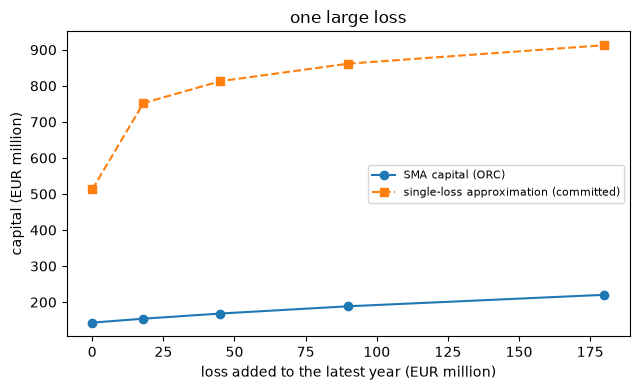

In [9]:
# Draw the SMA response against the single-loss-approximation response to a large loss added to the latest year
fig, ax = plt.subplots(figsize=(6.5, 4.0))
added = np.array([row["added_loss_eur"] for row in response["rows"]]) / 1e6
ax.plot(added, [row["orc_eur"] / 1e6 for row in response["rows"]], "o-", label="SMA capital (ORC)")
ax.plot(
    added, [row["lda_capital_eur"] / 1e6 for row in response["rows"]], "s--",
    label="single-loss approximation (committed)"
)
ax.set_xlabel("loss added to the latest year (EUR million)")
ax.set_ylabel("capital (EUR million)")
ax.set_title("one large loss")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The SMA line rises smoothly, from EUR 143,154,295 with no added loss to EUR 220,354,518 with EUR 180,000,000 added: the average over ten years and the concave multiplier absorb the shock. The distribution-based capital of the same history starts far higher, EUR 512.7 million, and jumps to EUR 752.2 million with the first added loss, because a single large loss becomes the tail of the fitted law. The two capitals answer different questions, and the figure does not say which is right; it shows that the SMA reacts weakly where the other reacts violently.

### B1: the expert scenarios

An expert gives scenarios as pairs of a loss and how often a loss at least that large happens. The case states eight of them for the synthetic bank, rounded to two significant figures as an expert would, from "a loss of EUR 190,000 four times a year" to "EUR 1.3 million once in two and a half years"; two of them are labelled as named events. The engine represents each as a `ScenarioPoint` with its kind, loss and exceedance frequency per year. The next cell builds the points from the committed block and prints them with their label in the language of the notebook.

In [10]:
# Build the engine's scenario points from the committed block
points = [
    scenarios.ScenarioPoint(
        s["scenario_id"], s["kind"], s["loss_eur"], s["exceedance_frequency_per_year"]
    ) for s in influence_block["scenarios"]
]
KIND = {"percentile": "percentile", "individual": "individual"}
for s, p in zip(influence_block["scenarios"], points):
    print(
        "%-3s %-10s EUR %10s | %5.2f a year | %s" % (
            p.scenario_id, KIND[p.kind], format(p.loss, ",.0f"), p.exceedance_frequency, s["label"][LANG]
        )
    )
rebuilt = replicate.scenario_points(variant)
print(
    "the case's own construction gives the same points:",
    all(a.loss == b.loss and a.exceedance_frequency == b.exceedance_frequency for a, b in zip(points, rebuilt))
)

S1  percentile EUR    190,000 |  4.00 a year | Loss four times a year
S2  percentile EUR    250,000 |  3.00 a year | Loss three times a year
S3  percentile EUR    350,000 |  2.00 a year | Loss twice a year
S4  percentile EUR    440,000 |  1.50 a year | Loss three times in two years
S5  percentile EUR    620,000 |  1.00 a year | Loss once a year
S6  individual EUR    780,000 |  0.75 a year | Named event: outage of the core platform
S7  percentile EUR  1,100,000 |  0.50 a year | Loss once in two years
S8  individual EUR  1,300,000 |  0.40 a year | Named event: large external fraud
the case's own construction gives the same points: True


### B2: scenarios as pseudo-observations, and as a fitted tail

Two simple ways to use scenarios. As **pseudo-observations**, each scenario is a loss that appears in the data $\text{frequency} \times \text{years}$ times, which `scenario_pseudo_observations` returns as losses and weights. As a **fitted tail**, each point implies the conditional probability of exceeding its loss given a loss above the tail threshold $u_s$, $\text{frequency}_j / f_{u_s}$, where $f_{u_s}$ is the expert's frequency of losses above $u_s$; a generalised Pareto is fitted by least squares on the logarithms of the excesses, as in notebook 02, with `fit_tail_to_scenarios`:

$$\min_{\xi,\beta}\; \sum_j \left[\ln\!\Big(\tfrac{\beta}{\xi}\big(c_j^{-\xi} - 1\big)\Big) - \ln(\ell_j - u_s)\right]^2, \qquad c_j = \frac{\text{frequency}_j}{f_{u_s}}$$

where $\ell_j$ is the scenario loss. The case uses $u_s$ = EUR 100,000 and $f_{u_s}$ = the true expected number of losses above it, rounded to two figures. The next cell prints the pseudo-observations for ten years and the fitted tail.

In [11]:
# Pseudo-observations for ten years, and the generalised Pareto fitted to the scenario points
U_S = case_params.SPLICE_THRESHOLD_EUR
f_above = replicate.expert_frequency_above_tail(variant)
losses_s, weights_s = scenarios.scenario_pseudo_observations(points, 10.0)
print("pseudo-observations (loss: weight):", {int(l): float(w) for l, w in zip(losses_s, weights_s)})
tail_fit = scenarios.fit_tail_to_scenarios(points, U_S, f_above)
print("expert frequency above EUR", int(U_S), ":", f_above)
print(
    "xi = %.4f (se %.4f) | beta = %.1f (se %.1f) | converged %s | true xi %.2f" % (
        tail_fit.params[0], tail_fit.std_errors[0], tail_fit.params[1], tail_fit.std_errors[1], tail_fit.converged,
        variant.tail_index
    )
)

pseudo-observations (loss: weight): {190000: 40.0, 250000: 30.0, 350000: 20.0, 440000: 15.0, 620000: 10.0, 780000: 7.5, 1100000: 5.0, 1300000: 4.0}
expert frequency above EUR 100000 : 8.6
xi = 0.8206 (se 0.0120) | beta = 87483.6 (se 1446.1) | converged True | true xi 0.80


The next cell draws the eight scenarios as points of loss against how often a loss that large happens, with the generalised Pareto tail fitted to them on logarithmic axes.

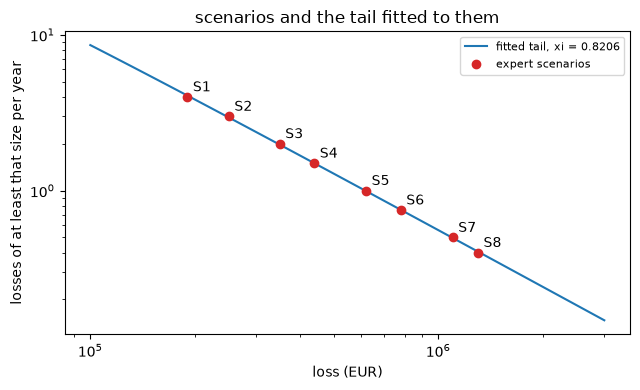

In [12]:
# Draw the eight scenario points and the generalised Pareto tail fitted to them
fig, ax = plt.subplots(figsize=(6.5, 4.0))
loss_grid = np.logspace(np.log10(U_S), np.log10(3_000_000), 100)
tail_params = (tail_fit.params[0], tail_fit.params[1], U_S)
fitted_rate = f_above * (1.0 - distributions.severity_cdf("gpd", tail_params, loss_grid))
ax.loglog(loss_grid, fitted_rate, color="tab:blue", label="fitted tail, xi = %.4f" % tail_fit.params[0])
ax.loglog(
    [q.loss for q in points], [q.exceedance_frequency for q in points], "o", color="tab:red", label="expert scenarios"
)
for q in points:
    ax.annotate(q.scenario_id, (q.loss, q.exceedance_frequency), textcoords="offset points", xytext=(4, 4))
ax.set_xlabel("loss (EUR)")
ax.set_ylabel("losses of at least that size per year")
ax.set_title("scenarios and the tail fitted to them")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The eight points fall almost on a straight line on these axes, from four losses a year of EUR 190,000 to 0.40 a year of EUR 1,300,000, and the fitted tail passes through them with a tail index of 0.8206 against the true 0.80. That closeness is partly built in: the case derives the experts' numbers from the generator and rounds them to two figures, as an expert would. The figure shows the scenarios are coherent with a power law; it does not show that real experts would be as coherent.

### B3: Bayesian credibility

The third method treats the scenarios as a **prior** on the tail and lets the loss data update it (Shevchenko and Wuthrich, 2006). For the one-parameter Pareto above $L$, $f(x \mid \alpha) = (\alpha/L)(x/L)^{-\alpha-1}$ with shape $\alpha = 1/\xi$, a Gamma prior on $\alpha$ with shape $a$ and rate $r$ updates, after $n$ losses $x_i \ge L$, to a Gamma posterior (Shevchenko and Wuthrich, 2006, section 3.3):

$$\alpha \mid x \sim \mathrm{Gamma}\big(a + n,\; r + S\big), \quad S = \sum_{i=1}^{n} \ln(x_i/L), \qquad \hat\alpha = w\,\hat\alpha_{\mathrm{MLE}} + (1 - w)\,\frac{a}{r}, \quad w = \frac{S}{S + r}, \quad \hat\alpha_{\mathrm{MLE}} = \frac{n}{S}$$

The posterior mean is a **credibility** weighting of the data estimate and the expert's mean: the more the data say ($S$ large against $r$), the closer to the data. The prior is built from the scenario fit: its mean is $1/\xi_s$ of B2 and its 90% interval comes from a parametric bootstrap of the scenario frequencies; the case's `scenario_prior` takes the first bootstrap seed whose refits all stay inside the engine's search bounds. The prior is not restricted to $\alpha > 1$, so a tail index of 1 or more stays possible. The next cell prints the prior, every term of the update from the history's 91 or so tail losses, and the identity of the credibility weighting.

In [13]:
# The prior from the scenarios, the update with the tail losses of the history, and the credibility identity
prior, bootstrap_seed = replicate.scenario_prior(variant, points, 10)
scenario_history = generator.draw_history(variant, influence_block["seed"], 10).recorded(H)
tail_losses = scenario_history.amounts[scenario_history.amounts >= U_S]
credibility = scenarios.credibility_pareto(prior, tail_losses, U_S)
s_total = float(np.log(tail_losses / U_S).sum())
print(
    "prior: shape, rate, mean of alpha, 90%% interval: %.3f, %.3f, %.4f, (%.3f, %.3f) | bootstrap seed %d" % (
        prior.shape, prior.rate, prior.mean, prior.interval[0], prior.interval[1], bootstrap_seed
    )
)
print(
    "n = %d | S = %.4f | posterior: shape, rate: %.3f, %.4f" % (
        credibility.n, s_total, credibility.posterior_shape, credibility.posterior_rate
    )
)
print("alpha_MLE = n / S = %.4f | w = S / (S + r) = %.4f" % (credibility.n / s_total, s_total / (s_total + prior.rate)))
print(
    "w * alpha_MLE + (1 - w) * a / r = %.6f | posterior mean = %.6f" % (
        credibility.credibility_weight * credibility.alpha_mle + (1 - credibility.credibility_weight) * prior.mean,
        credibility.alpha_mean
    )
)
print(
    "xi = 1 / alpha = %.4f | beta = xi * L = %.1f | infinite mean %s | true xi %.2f" % (
        credibility.xi, credibility.beta, credibility.infinite_mean, variant.tail_index
    )
)

prior: shape, rate, mean of alpha, 90% interval: 54.104, 44.397, 1.2186, (1.012, 4.418) | bootstrap seed 0
n = 91 | S = 79.6431 | posterior: shape, rate: 145.104, 124.0403
alpha_MLE = n / S = 1.1426 | w = S / (S + r) = 0.6421
w * alpha_MLE + (1 - w) * a / r = 1.169809 | posterior mean = 1.169809
xi = 1 / alpha = 0.8548 | beta = xi * L = 85484.0 | infinite mean False | true xi 0.80


### B4: the capital the scenarios give, and the influence of each scenario

The case's scenario rung takes the splice of notebook 02 (lognormal body, tail above EUR 100,000) and replaces its Pareto tail with the credibility tail, then aggregates by the Panjer recursion (notebook 03). The influence of scenario $i$ is the relative change of the 99.9% capital when the scenario is removed and the prior is rebuilt from the remaining ones (the prior is the expert's, so it moves with them):

$$I_i = \frac{C_{\text{all}} - C_{\text{without } i}}{C_{\text{all}}}$$

`scenario_influence` calls the capital function once for all scenarios and once for each omission. The test `oprisk.scenario_influence` takes the largest absolute influence and colours it against an internal gate (green up to 0.10, amber up to 0.25, red above). The next cell computes the capital with the scenarios and the splice-only capital of the same history for contrast, then the eight influences (about two seconds), and runs the test. The committed block is on the same history.

In [14]:
# The capital with the scenarios, the splice-only capital, the eight influences, and the test
lam_hat = distributions.fit_frequency(scenario_history.counts).params[0]
splice = distributions.fit_splice(scenario_history.amounts, H, U_S)
capital_with = replicate.scenario_capital(scenario_history, lam_hat, splice, prior)
cache = {}


def capital_without(subset):
    # the capital of the scenario rung for a subset of the points (the prior is rebuilt from them)
    key = tuple(p.scenario_id for p in subset)
    if key not in cache:
        cache[key] = replicate.scenario_capital(
            scenario_history, lam_hat, splice, replicate.scenario_prior(variant, list(subset), 10)[0]
        )
    return cache[key]


influences = scenarios.scenario_influence(points, capital_without)
print(
    "capital with the scenarios (EUR): %s | committed %s" % (
        format(capital_with, ",.0f"), format(influence_block["base_capital_eur"], ",.0f")
    )
)
print(
    "true 99.9% quantile (EUR):", format(variant_doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"], ",.0f")
)
for s, i in zip(influence_block["scenarios"], influences):
    print("%-3s influence %+.4f | committed %+.4f" % (s["scenario_id"], i, s["influence"]))
influence_test = oprisk_tests.scenario_influence(influences, model_id="scenario")
print(
    "test: largest absolute influence %.4f | light %s | gates %s" % (
        influence_test.metric, influence_test.light.value, influence_test.extras["thresholds"]
    )
)

capital with the scenarios (EUR): 247,029,041 | committed 247,029,041
true 99.9% quantile (EUR): 163,483,000
S1  influence +0.0828 | committed +0.0828
S2  influence +0.0081 | committed +0.0081
S3  influence -0.0390 | committed -0.0390
S4  influence -0.0397 | committed -0.0397
S5  influence -0.0318 | committed -0.0318
S6  influence -0.0137 | committed -0.0137
S7  influence -0.0317 | committed -0.0317
S8  influence -0.0653 | committed -0.0653
test: largest absolute influence 0.0828 | light green | gates {'influence_amber': 0.1, 'influence_red': 0.25}


The next cell draws the influence of each scenario on the credibility capital, the relative gap between the capital with all scenarios and without that one, against the amber gate of the engine's test.

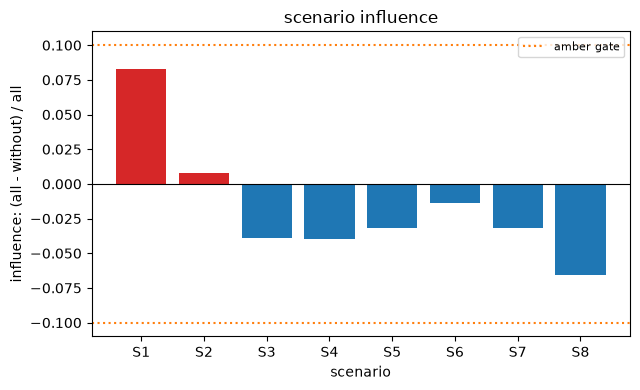

In [15]:
# Draw the influence of each scenario on the credibility capital
fig, ax = plt.subplots(figsize=(6.5, 4.0))
ids = [s["scenario_id"] for s in influence_block["scenarios"]]
ax.bar(ids, influences, color=["tab:red" if i > 0 else "tab:blue" for i in influences])
ax.axhline(0.0, color="black", linewidth=0.8)
ax.axhline(0.10, color="tab:orange", linestyle=":", label="amber gate")
ax.axhline(-0.10, color="tab:orange", linestyle=":")
ax.set_xlabel("scenario")
ax.set_ylabel("influence: (all - without) / all")
ax.set_title("scenario influence")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

With S1, the most frequent scenario, in the set the capital is 0.0828 of its value higher than without it, the largest bar, and with S8, the large external fraud, it is 0.0653 lower. Every bar stays inside the dotted gates, so the engine's test colours the set green: no single scenario decides the capital. The signs are informative too: the four mid-sized scenarios S3 to S5 and S7 all pull the capital down when present. The figure measures influence on this one history; another seed would redraw the bars.

## Results

**Answer:** For the synthetic bank the loss component is EUR 75,080,862, 0.4171 of the business indicator component of EUR 180,000,000, so the SMA multiplier is 0.795302 and the capital EUR 143,154,295. Adding a loss of EUR 180,000,000 to the latest year lifts it only to EUR 220,354,518 (multiplier 1.224192), a smooth response. Eight expert scenarios used as a credibility prior give EUR 247,029,041 against a true quantile of EUR 163,483,000, and the largest influence of one scenario is 0.0828.

- **The business indicator.** The averages inside the formulas give an interest, leases and dividend component of EUR 800 million, a services component of EUR 500 million and a financial component of EUR 100 million, an indicator of EUR 1.4 billion equal to the document's. The component is EUR 180 million (bucket 2). The golden value of the Basel text is reproduced by hand and by the engine: an indicator of EUR 35 billion gives EUR 5.37 billion.
- **The loss component and the multiplier.** The regenerated history has an average annual loss of EUR 5.0 million, a loss component of EUR 75.08 million, 0.417 times the component of the indicator, and so a multiplier of 0.7953, below 1, and a capital of EUR 143.15 million, equal to the committed row to the rounding of the file. With 4 years of losses the engine returns the component only, EUR 180 million, with the discretion `transitional-bic-only`.
- **One large loss.** Adding EUR 18, 45, 90 and 180 million to the latest year moves the multiplier to 0.856, 0.935, 1.047 and 1.224 and the capital to EUR 154.1, 168.4, 188.5 and 220.4 million, every row equal to the committed one. Half the component (EUR 90 million) makes the multiplier jump by 0.252, and `oprisk.sma_ilm_response` is red against its internal gate of 0.15. The committed single-loss-approximation capital of the same history rises from EUR 512.7 million to EUR 912.8 million over the same additions.
- **The scenarios as a tail.** The eight scenarios fitted by least squares give a tail index of 0.8206 (standard error 0.012) and a scale of EUR 87,484, against a true tail index of 0.80; as pseudo-observations they weigh from 40 down to 4 events in ten years.
- **Credibility.** The prior on the Pareto shape has mean 1.2186, a tail index of about 0.82, with a 90% interval from 1.012 to 4.418. The 91 losses above EUR 100,000 have $S$ = 79.64 and an estimate from the data alone of 1.1426; the credibility weight is 0.642, and the posterior mean 1.1698 equals the weighted average of the data estimate and the prior mean to six decimals. The updated tail index is 0.8548, still a finite mean.
- **The capital and the influences.** The capital with the scenarios is EUR 247.03 million, equal to the committed block, 1.51 times the true quantile of EUR 163.48 million. The influence of each scenario is between -6.5% (S8) and +8.3% (S1), the committed values to four decimals, and `oprisk.scenario_influence` is green with its largest absolute influence of 0.0828 against the amber gate of 0.10.

What this notebook does not show: how stable the capital of each method is across histories (notebook 06 and the level 4 notebook), or how the SMA compares with the LDA across tail indices (notebook 07).

## Summary

- The SMA is a formula: the business indicator gives the component by buckets, the average of ten years of losses gives the loss component, and a concave multiplier ties them; the engine reproduces the Basel golden value.
- One large loss moves the SMA smoothly through the multiplier; the internal gate on the jump of the multiplier is Contraste's own and flags a loss of half the component as red.
- Scenarios can enter a tail model as pseudo-observations, as a fitted tail or as a Gamma prior; the credibility posterior mean is exactly a weighted average of the data estimate and the expert's mean.
- The influence of each scenario on the capital is measurable, and here the largest is 8.3%.

**What to try next.** Remove scenario S1 and S8 together and rebuild the prior from the other six to see the capital move. Add a loss of two times the component to the SMA history and watch the multiplier pass 1.3. Continue with notebook 06.

## References

- BCBS, Basel Framework OPE25, Calculation of RWA for operational risk (the standardised approach), in force 2023-01-01. https://www.bis.org/basel_framework/chapter/OPE/25.htm
- Shevchenko, P. V. and Wuthrich, M. V. (2006), The structural modeling of operational risk via Bayesian inference: combining loss data with expert opinions, Journal of Operational Risk 1(3), 3-26. https://doi.org/10.21314/JOP.2006.016